In [2]:
import numpy as np
import pandas as pd
import kagglehub
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, roc_curve, ConfusionMatrixDisplay

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from catboost import CatBoostClassifier
from sklearn.metrics import precision_recall_curve

In [3]:
path = kagglehub.dataset_download("yashdevladdha/uber-ride-analytics-dashboard")

print("Path to dataset files:", path)

Path to dataset files: /home/annah/.cache/kagglehub/datasets/yashdevladdha/uber-ride-analytics-dashboard/versions/2


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression

In [5]:
ls /home/annah/.cache/kagglehub/datasets/yashdevladdha/uber-ride-analytics-dashboard/versions/2

Dasboard.gif  ncr_ride_bookings.csv  Uber.pbix


In [6]:
df = pd.read_csv\
("/home/annah/.cache/kagglehub/datasets/yashdevladdha/uber-ride-analytics-dashboard/versions/2/ncr_ride_bookings.csv")

In [7]:
df.head()

,Date,Time,Booking ID,Booking Status,Customer ID,Vehicle Type,Pickup Location,Drop Location,Avg VTAT,Avg CTAT,...,Reason for cancelling by Customer,Cancelled Rides by Driver,Driver Cancellation Reason,Incomplete Rides,Incomplete Rides Reason,Booking Value,Ride Distance,Driver Ratings,Customer Rating,Payment Method
0,2024-03-23,12:29:38,"""CNR5884300""",No Driver Found,"""CID1982111""",eBike,Palam Vihar,Jhilmil,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-11-29,18:01:39,"""CNR1326809""",Incomplete,"""CID4604802""",Go Sedan,Shastri Nagar,Gurgaon Sector 56,4.9,14.0,...,NaN,NaN,NaN,1.0,Vehicle Breakdown,237.0,5.73,NaN,NaN,UPI
2,2024-08-23,08:56:10,"""CNR8494506""",Completed,"""CID9202816""",Auto,Khandsa,Malviya Nagar,13.4,25.8,...,NaN,NaN,NaN,NaN,NaN,627.0,13.58,4.9,4.9,Debit Card
3,2024-10-21,17:17:25,"""CNR8906825""",Completed,"""CID2610914""",Premier Sedan,Central Secretariat,Inderlok,13.1,28.5,...,NaN,NaN,NaN,NaN,NaN,416.0,34.02,4.6,5.0,UPI
4,2024-09-16,22:08:00,"""CNR1950162""",Completed,"""CID9933542""",Bike,Ghitorni Village,Khan Market,5.3,19.6,...,NaN,NaN,NaN,NaN,NaN,737.0,48.21,4.1,4.3,UPI


In [8]:
df["driver_cancel"] = df["Booking Status"] == "Cancelled by Driver"
print(df.groupby("Pickup Location")["driver_cancel"].mean().describe())
print(df.groupby("Vehicle Type")["driver_cancel"].mean())
print(df.groupby("Booking Value")["driver_cancel"].mean())

print(df.groupby(pd.to_datetime(df["Time"]).dt.hour)["driver_cancel"].mean())

count    176.000000
mean       0.180002
std        0.014011
min        0.145251
25%        0.170194
50%        0.179676
75%        0.188250
max        0.214689
Name: driver_cancel, dtype: float64
Vehicle Type
Auto             0.177530
Bike             0.181063
Go Mini          0.178823
Go Sedan         0.185365
Premier Sedan    0.179449
Uber XL          0.171274
eBike            0.180638
Name: driver_cancel, dtype: float64
Booking Value
50.0      0.0
51.0      0.0
52.0      0.0
53.0      0.0
54.0      0.0
         ... 
4133.0    0.0
4202.0    0.0
4220.0    0.0
4228.0    0.0
4277.0    0.0
Name: driver_cancel, Length: 2566, dtype: float64


/tmp/ipykernel_114374/1979198446.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  print(df.groupby(pd.to_datetime(df["Time"]).dt.hour)["driver_cancel"].mean())


Time
0     0.180626
1     0.183824
2     0.165795
3     0.190166
4     0.181681
5     0.190955
6     0.168029
7     0.184587
8     0.177962
9     0.181200
10    0.179075
11    0.174136
12    0.178989
13    0.182998
14    0.186460
15    0.179468
16    0.179383
17    0.181365
18    0.182060
19    0.180864
20    0.180166
21    0.172158
22    0.185811
23    0.175959
Name: driver_cancel, dtype: float64


In [9]:
df["hour"] = pd.to_datetime(df["Time"], format="%H:%M:%S").dt.hour
df["dow"] = pd.to_datetime(df["Date"]).dt.dayofweek

In [10]:
cat_cols = ["Pickup Location", "Drop Location", "Vehicle Type", "hour", "dow"]

print(df[cat_cols].isna().sum())

Pickup Location    0
Drop Location      0
Vehicle Type       0
hour               0
dow                0
dtype: int64


In [11]:
print(df.groupby("Booking Status")["Avg VTAT"].apply(lambda s: s.isna().mean()))
print(df.groupby("driver_cancel")["Avg VTAT"].describe())

Booking Status
Cancelled by Customer    0.0
Cancelled by Driver      0.0
Completed                0.0
Incomplete               0.0
No Driver Found          1.0
Name: Avg VTAT, dtype: float64
                  count      mean       std  min  25%  50%   75%   max
driver_cancel                                                         
False          112500.0  8.685408  3.970272  2.0  5.4  8.5  11.9  20.0
True            27000.0  7.501952  2.600695  3.0  5.2  7.5   9.8  12.0


Best threshold: 
0.1735619995526913


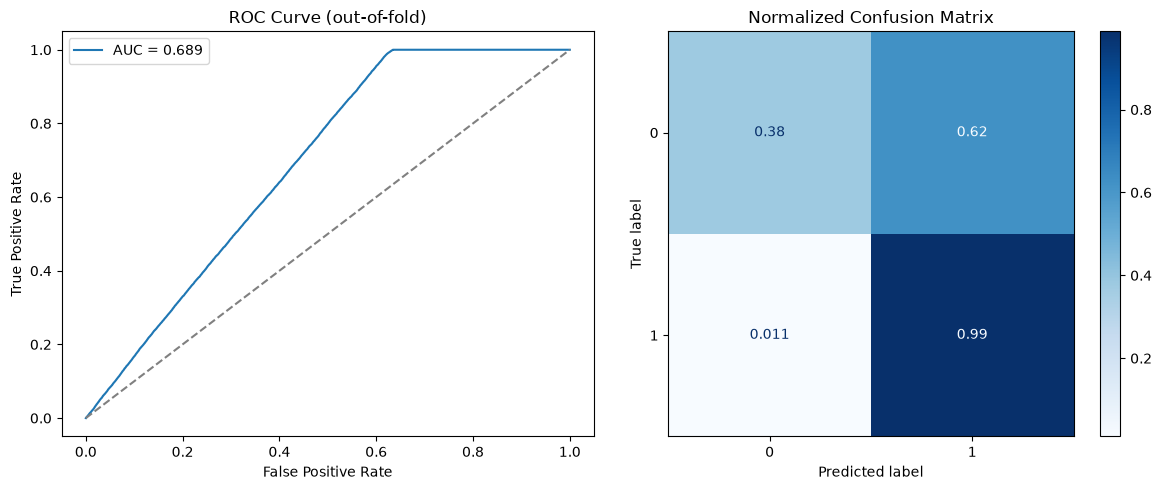

all:         0.6894176934658236
Best threshold: 
0.11766959438467324


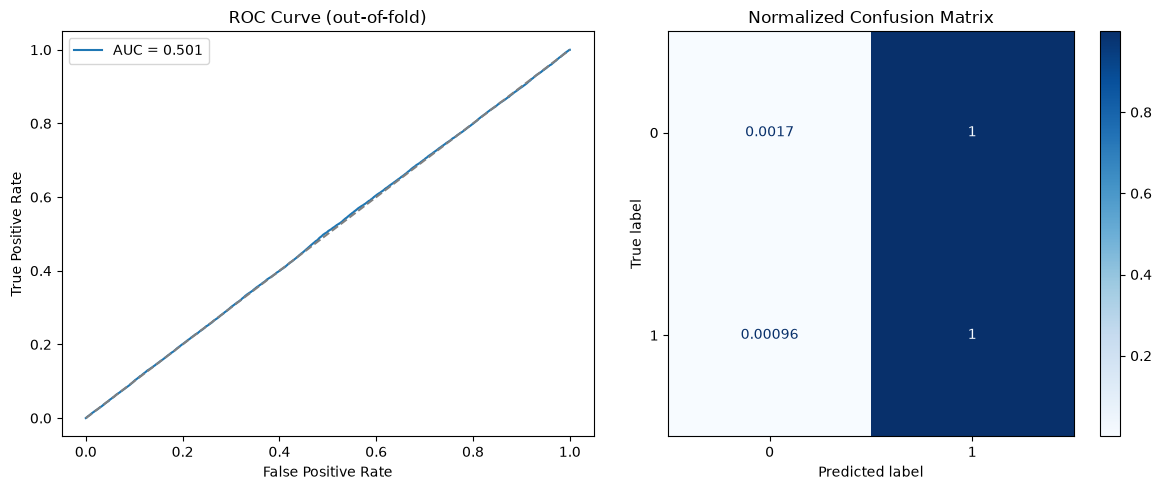

no VTAT:     0.5013507324601024
Best threshold: 
0.21479605711179633


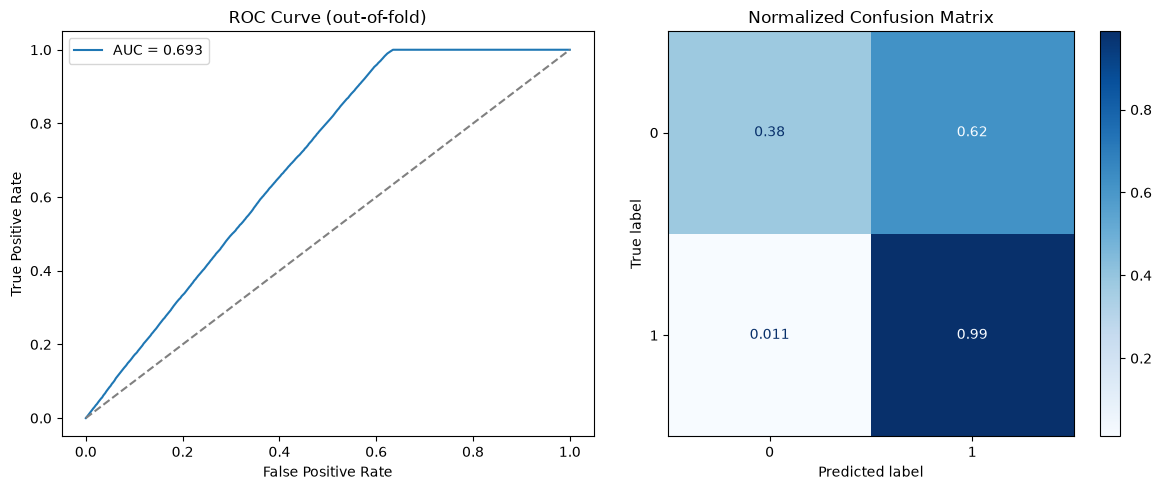

VTAT only:   0.6931202288467329


In [13]:
y = df["driver_cancel"].astype(int)
def cv_auc(features):
    X = df[features]
    cats = [c for c in features if c in cat_cols] 
    aucs = []
    y_prob = np.zeros(len(y))
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=0).split(X, y):
        clf = CatBoostClassifier(cat_features=cats, verbose=0)
        clf.fit(X.iloc[tr], y.iloc[tr])
        prediction = clf.predict_proba(X.iloc[te])[:,1]
        y_prob[te] = prediction
        aucs.append(roc_auc_score(y.iloc[te], prediction))
    
    y_true = y.values
    precision, recall, thresholds = precision_recall_curve(y_true, y_prob)
    f1 = 2 * precision * recall / (precision + recall + 1e-9)
    best_threshold = thresholds[f1[:-1].argmax()]
    print("Best threshold: ")
    print(best_threshold)
    y_pred = (y_prob >= best_threshold).astype(int)


    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # ROC curve
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    axes[0].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_true, y_prob):.3f}")
    axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
    axes[0].set_xlabel("False Positive Rate")
    axes[0].set_ylabel("True Positive Rate")
    axes[0].set_title("ROC Curve (out-of-fold)")
    axes[0].legend()

    # Normalized confusion matrix
    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred, normalize="true", ax=axes[1], cmap="Blues"
    )
    axes[1].set_title(f"Normalized Confusion Matrix")

    plt.tight_layout()
    plt.show()
    
    return sum(aucs) / len(aucs)

feats_all = cat_cols + ["Avg VTAT"]
feats_no_vtat = cat_cols
feats_vtat_only = ["Avg VTAT"]

print("all:        ", cv_auc(feats_all))
print("no VTAT:    ", cv_auc(feats_no_vtat))
print("VTAT only:  ", cv_auc(feats_vtat_only))